# RQ4: Where do the two convergence tests disagree?

**Author:** Uyazi Dube · EU Regional Convergence project (Data Analytics)

**Question.** Sigma convergence (RQ1A) asks whether the *spread* of GDP per inhabitant across EU regions is shrinking. Beta convergence (RQ2) asks whether *poorer regions grow faster* than richer ones. This notebook compares the two tests, identifies where and why they disagree, and decides which conclusion is better supported.

**Data.** `data/processed/eu_nuts2_master_panel.csv`: 244 EU NUTS 2 regions, 2016–2024, GDP per inhabitant in PPS as an index (EU27 = 100). GDP is complete for all regions and years. The balanced panel (224 regions) is used as a robustness check.

**Code.** All calculations are in `src/11_rq4_sigma_vs_beta.py`. This notebook runs that script and presents its outputs (`outputs/rq4/`).

## Method

| Step | What | Why |
|---|---|---|
| 1. Sigma | Dispersion each year with three measures: SD of log GDP, coefficient of variation (CV), P90/P10 ratio | Different measures weight the tails differently |
| 2. Beta | OLS of annualised log growth 2016–2024 on log GDP 2016, robust (HC1) standard errors, speed of convergence and half-life | Standard absolute beta-convergence test |
| 3. Year by year | Annual beta vs annual change in sigma | Shows *when* the tests disagree |
| 4. Decomposition | $\mathrm{Var}(y_T) = (1+B)^2\,\mathrm{Var}(y_0) + \mathrm{Var}(\varepsilon)$ | Links the two tests: sigma falls only if the catch-up effect (beta) outweighs new region-specific shocks |
| 5. Between / within | Variance of log GDP split into between-country and within-country parts | Shows *where* convergence happens |
| 6. Exceptions | Regions and countries going against the EU-wide pattern | Answers "identify exceptions" |

**Outlier regions** (sensitivity check): LU00 Luxembourg and BE10 Brussels (commuter regions), IE05 and IE06 Ireland (GDP inflated by multinational profit booking).

Beta being negative is *necessary but not sufficient* for sigma convergence (Sala-i-Martin, 1996; Quah, 1993), which is why the two tests can disagree.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

# works whether the notebook is opened from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
OUT = ROOT / "outputs" / "rq4"
pd.set_option("display.precision", 4)

%run "{ROOT}/src/11_rq4_sigma_vs_beta.py"

Regions: 244  years: 2016-2024


RQ4 SUMMARY: sigma vs beta convergence, EU NUTS 2, 2016-2024

BETA (full period)
  All regions:      beta = -0.0167 (t = -7.0), R2 = 0.24, half-life = 39 years
  Without outliers: beta = -0.0187, R2 = 0.28
  Within countries: beta = -0.0050 (t = -2.0)
  Between countries: beta = -0.0201 (t = -3.2)

SIGMA (% change 2016 -> 2024)
  sd_log                 -10.1%  (rose in 1 of 8 years)
  cv                     -4.6%  (rose in 3 of 8 years)
  p90_p10                -15.8%  (rose in 1 of 8 years)
  sd_log_excl_outliers   -11.7%  (rose in 1 of 8 years)
  cv_excl_outliers       -7.8%  (rose in 1 of 8 years)

WHERE THEY DISAGREE
  Years where beta < 0 but CV rose:          2019-2020, 2020-2021, 2021-2022
  Years where beta < 0 but SD of log rose:   2019-2020
  Poor regions (<75) that fell further behind: 17
  Rich regions (>125) that pulled further ahead: 13
  Countries whose own regions diverged (sigma): BG, DK, EL, ES, HU, PT, RO

LINKING THE TWO TESTS (variance of log GDP, 2016-2024)
  All 

## 1. Sigma convergence: the answer depends on the measure

,start,end,pct_change,trend_per_year,years_rising
sd_log,0.3949,0.3551,-10.0880,-0.0047,1
cv,0.3977,0.3796,-4.5658,-0.0015,3
p90_p10,2.7634,2.3281,-15.7540,-0.0559,1
sd_log_excl_outliers,0.3797,0.3355,-11.6597,-0.0054,1
cv_excl_outliers,0.3675,0.3387,-7.8222,-0.0034,1


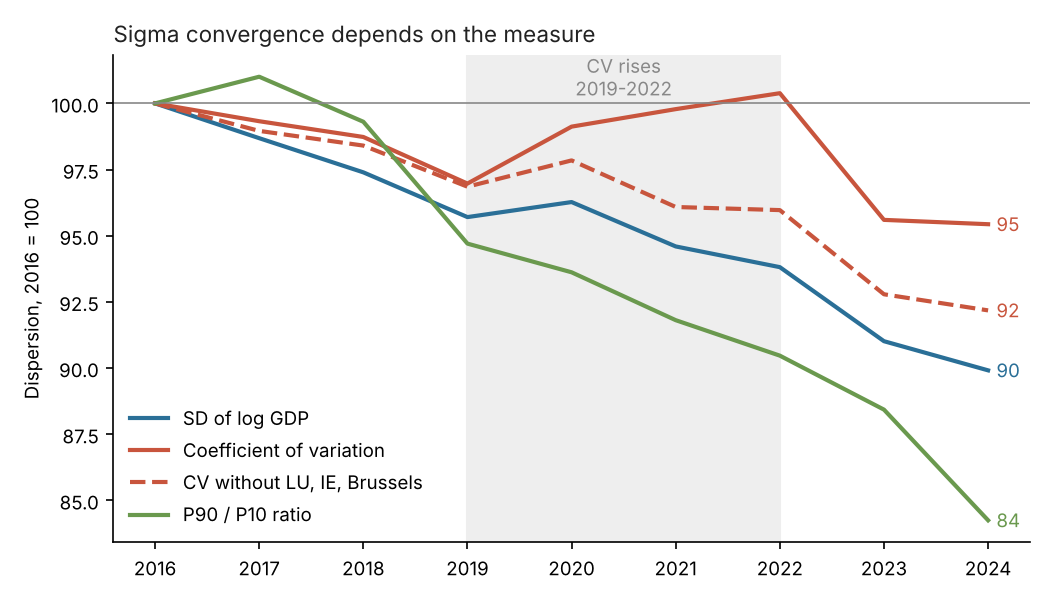

In [2]:
display(pd.read_csv(OUT / "rq4_sigma_trend_summary.csv", index_col=0))
display(Image(OUT / "fig1_sigma_measures.png"))

All measures are lower in 2024 than in 2016, but by very different amounts: P90/P10 −16%, SD of log −10%, CV only −5%. The **CV rises from 2019 to 2022**, while the log measure rises only in 2020. Without the four outlier regions, the CV also falls after 2020. The CV is sensitive to the top of the distribution, and a few very rich regions pulled away in those years (Eastern & Midland Ireland 201 → 268, Bucharest 136 → 188).

## 2. Beta convergence: poorer regions grow faster

,specification,n,beta,se_hc1,t_stat,r2,speed_lambda,half_life_years
0,All regions (master panel),244,-0.0167,0.0024,-6.9560,0.2371,0.0179,38.7851
1,Without outlier regions,240,-0.0187,0.0022,-8.3551,0.2820,0.0202,34.2836
2,Balanced panel regions,224,-0.0164,0.0026,-6.2821,0.2215,0.0176,39.4677
3,Within countries (country-demeaned),244,-0.0050,0.0025,-2.0486,0.0402,0.0051,134.9870
4,Between countries (country means),27,-0.0201,0.0063,-3.2027,0.3307,0.0219,31.6163


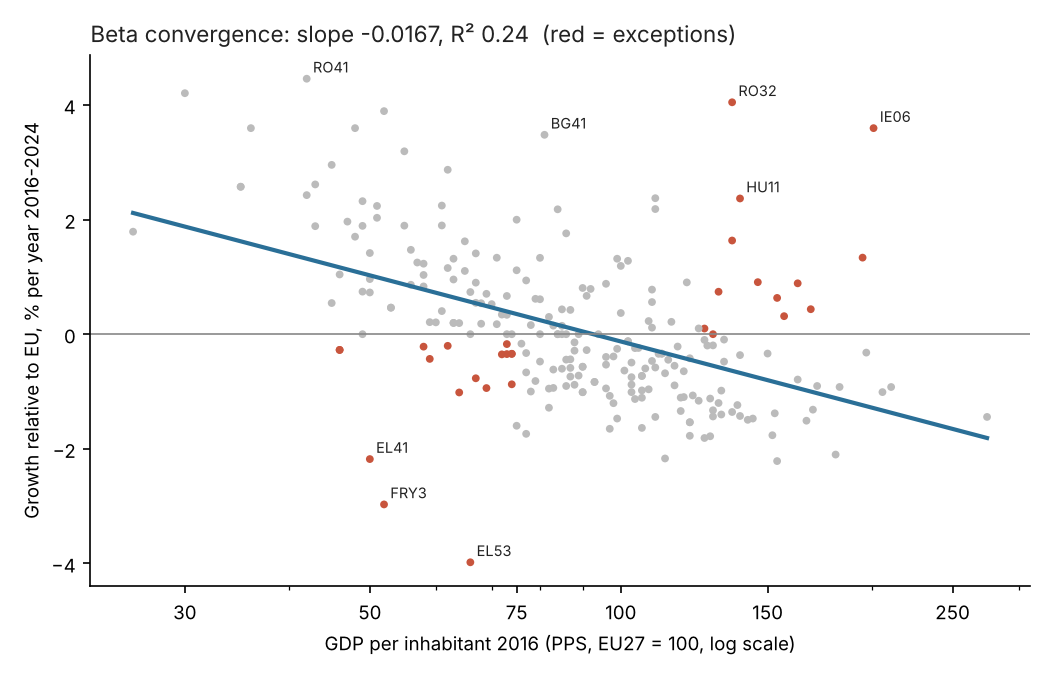

In [3]:
display(pd.read_csv(OUT / "rq4_beta_results.csv"))
display(Image(OUT / "fig2_beta_scatter.png"))

Beta = −0.0167 per year (t = −7.0, R² = 0.24), giving a half-life of about 39 years. The result is robust: it is slightly stronger without the outliers (−0.0187) and almost identical in the balanced panel (−0.0164). **Within countries, beta is much weaker** (−0.0050, only just significant; half-life ≈ 135 years). Between countries it is strong (−0.0201). So the catch-up is mainly poorer *countries* catching up, not poorer regions inside a country.

## 3. Year by year: when do the tests disagree?

In [4]:
annual = pd.read_csv(OUT / "rq4_annual_agreement.csv")
annual

,period,beta,beta_significant_5pct,change_sd_log,change_cv,beta_says,sd_log_says,cv_says,agree_sd_log,agree_cv
0,2016-2017,-0.0151,True,-0.0052,-0.0027,converging,converging,converging,True,True
1,2017-2018,-0.0149,True,-0.0051,-0.0024,converging,converging,converging,True,True
2,2018-2019,-0.0192,True,-0.0067,-0.0070,converging,converging,converging,True,True
3,2019-2020,-0.0041,False,0.0022,0.0086,converging,diverging,diverging,False,False
4,2020-2021,-0.0223,True,-0.0066,0.0026,converging,converging,diverging,True,False
5,2021-2022,-0.0151,False,-0.0031,0.0024,converging,converging,diverging,True,False
6,2022-2023,-0.0350,True,-0.0111,-0.0190,converging,converging,converging,True,True
7,2023-2024,-0.0136,True,-0.0043,-0.0006,converging,converging,converging,True,True


Beta is negative in **every** period, but:
- **2019–2020 (COVID):** beta is weak and not significant, and sigma rises on both measures. This is a real disagreement.
- **2020–2021 and 2021–2022:** the log measure agrees with beta, but the CV does not. This disagreement is driven by the measure (the outliers).

## 4. Linking the two tests: catch-up vs new shocks

,period,sample,var_start,var_end,change,catch_up_effect,shock_effect,check_sum
0,2016-2024,all,0.1553,0.1256,-0.0298,-0.0386,0.0089,-0.0298
1,2016-2024,excl. outliers,0.1436,0.1121,-0.0315,-0.0397,0.0082,-0.0315
2,2016-2017,all,0.1553,0.1513,-0.0041,-0.0047,0.0006,-0.0041
3,2017-2018,all,0.1513,0.1473,-0.0039,-0.0045,0.0005,-0.0039
4,2018-2019,all,0.1473,0.1423,-0.0051,-0.0056,0.0005,-0.0051
5,2019-2020,all,0.1423,0.1440,0.0017,-0.0012,0.0029,0.0017
6,2020-2021,all,0.1440,0.1390,-0.0050,-0.0064,0.0014,-0.0050
7,2021-2022,all,0.1390,0.1367,-0.0023,-0.0042,0.0019,-0.0023
8,2022-2023,all,0.1367,0.1287,-0.0080,-0.0094,0.0014,-0.0080
9,2023-2024,all,0.1287,0.1256,-0.0031,-0.0035,0.0004,-0.0031


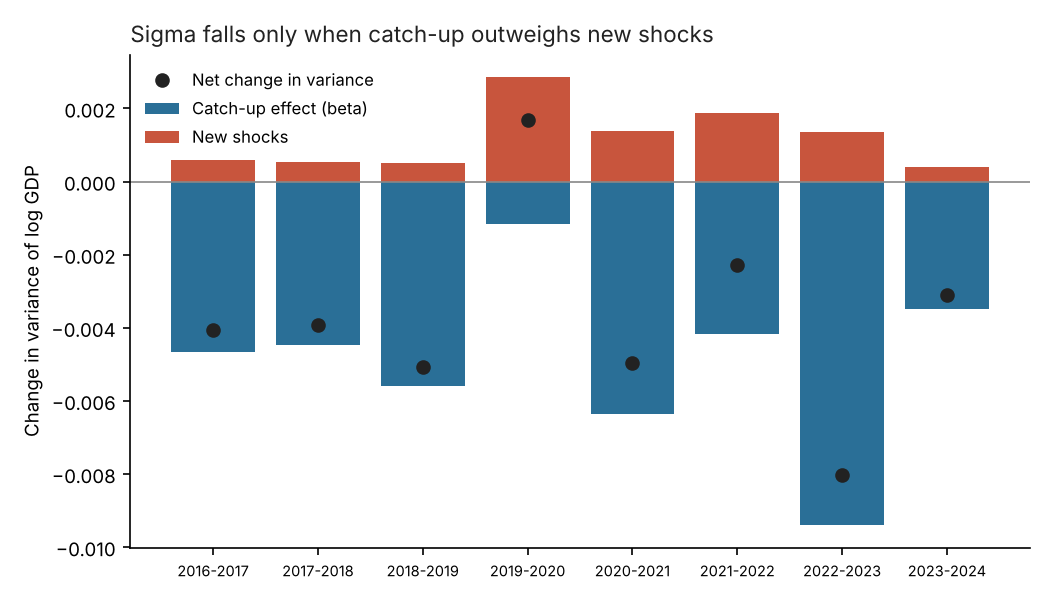

In [5]:
display(pd.read_csv(OUT / "rq4_variance_decomposition.csv"))
display(Image(OUT / "fig3_variance_decomposition.png"))

The decomposition is exact (`check_sum` = `change`). In every year, catch-up from beta reduces the variance, while new region-specific shocks increase it. Over 2016–2024, catch-up (−0.039) is about four times larger than the shocks (+0.009), so sigma falls. **2019–2020 is the only year when the shocks win**: the pandemic hit some regional economies (tourism, services) much harder than others, so dispersion rose even though poorer regions still grew slightly faster.

## 5. Between vs within countries

,total,between_countries,within_countries,share_within
year,,,,
2016,0.1553,0.0861,0.0692,0.4454
2017,0.1513,0.0830,0.0682,0.4510
2018,0.1473,0.0785,0.0689,0.4675
2019,0.1423,0.0727,0.0696,0.4892
2020,0.1439,0.0787,0.0652,0.4532
2021,0.1390,0.0738,0.0652,0.4689
2022,0.1367,0.0702,0.0665,0.4867
2023,0.1287,0.0623,0.0664,0.5160
2024,0.1256,0.0592,0.0664,0.5288


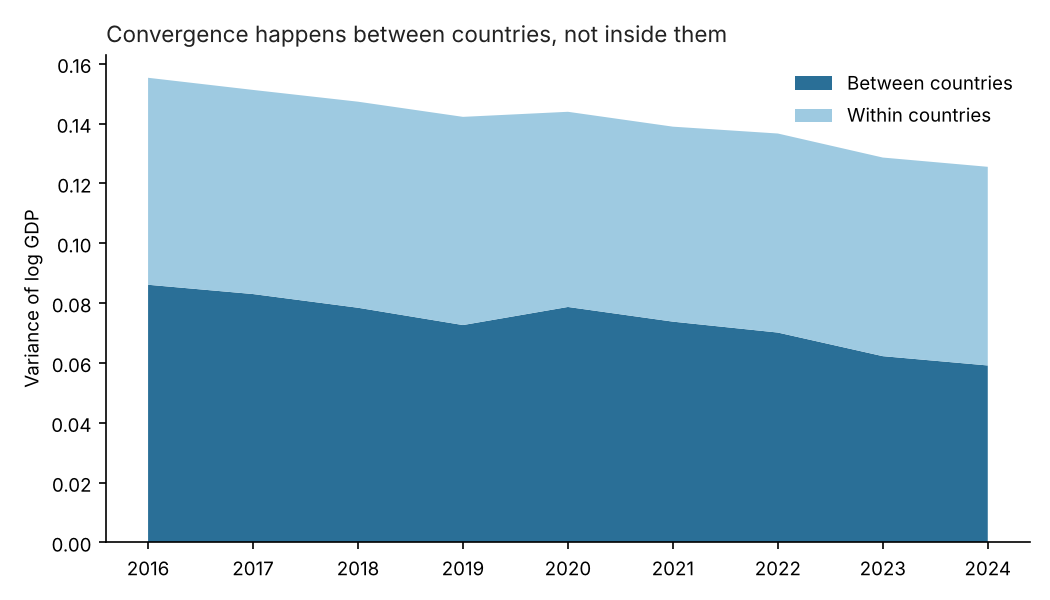

In [6]:
display(pd.read_csv(OUT / "rq4_between_within.csv", index_col=0))
display(Image(OUT / "fig4_between_within.png"))

Between-country inequality falls by 31%, within-country inequality only by 4%. By 2024 **more than half (53%) of regional inequality is inside countries**, up from 45%.

## 6. Exceptions

In [7]:
countries = pd.read_csv(OUT / "rq4_country_within_convergence.csv")
countries

,country,n_regions,sd_log_2016,sd_log_2024,sd_change_pct,within_beta,sigma_says,beta_says,richest_region_2024,tests_agree
0,EL,13,0.1949,0.2212,13.5174,-0.0012,diverging,converging,EL30 Attiki,False
1,DK,5,0.2272,0.2564,12.8719,0.0122,diverging,diverging,DK01 Hovedstaden,True
2,PT,9,0.2228,0.2404,7.9294,0.0079,diverging,diverging,PT1A Grande Lisboa,True
3,HU,8,0.3924,0.4129,5.2433,0.0025,diverging,diverging,HU11 Budapest,True
4,RO,8,0.4013,0.4205,4.7673,0.0042,diverging,diverging,RO32 Bucureşti-Ilfov,True
5,BG,6,0.3509,0.3580,2.0049,0.0010,diverging,diverging,BG41 Yugozapaden,True
6,ES,19,0.2071,0.2105,1.6600,0.0003,diverging,diverging,ES30 Comunidad de Madrid,True
7,BE,11,0.3204,0.3197,-0.2251,-0.0019,converging,converging,BE10 Région de Bruxelles-Capitale/Brussels Hoo...,True
8,SE,8,0.1775,0.1764,-0.6267,-0.0041,converging,converging,SE11 Stockholm,True
9,CZ,8,0.3574,0.3496,-2.1740,-0.0031,converging,converging,CZ01 Praha,True


In 7 of 19 countries with at least four regions, the gap between their own regions **widened**: Greece, Denmark, Portugal, Hungary, Romania, Bulgaria and Spain. In most of these, the capital region is pulling ahead (Budapest, Bucharest, Lisbon, Copenhagen, Athens). Greece is the one case where the two tests disagree inside a country: beta is slightly negative but sigma rises.

In [8]:
regions = pd.read_csv(OUT / "rq4_region_exceptions.csv", index_col=0)
cols = ["region_name", "country", "index_2016", "index_2024", "change_points", "pattern"]
print(regions["pattern"].value_counts(), "\n")
regions.loc[regions["pattern"].str.contains("exception"), cols].sort_values("change_points")

pattern
middle group                               116
poor, catching up (fits beta)               65
rich, losing ground (fits beta)             33
poor, falling behind (exception)            17
rich, pulling further ahead (exception)     13
Name: count, dtype: int64 



,region_name,country,index_2016,index_2024,change_points,pattern
region_code,,,,,,
EL53,Dytiki Makedonia,EL,66,48,-18,"poor, falling behind (exception)"
FRY3,Guyane,FR,52,41,-11,"poor, falling behind (exception)"
EL41,Voreio Aigaio,EL,50,42,-8,"poor, falling behind (exception)"
ES64,Ciudad de Melilla,ES,64,59,-5,"poor, falling behind (exception)"
ES63,Ciudad de Ceuta,ES,69,64,-5,"poor, falling behind (exception)"
FRY2,Martinique,FR,74,69,-5,"poor, falling behind (exception)"
FRY4,La Réunion,FR,67,63,-4,"poor, falling behind (exception)"
ITF6,Calabria,IT,59,57,-2,"poor, falling behind (exception)"
ES70,Canarias,ES,74,72,-2,"poor, falling behind (exception)"


**17 poor regions (index < 75) fell further behind**: mainly in Greece (Dytiki Makedonia −18 points, the North Aegean), the French overseas regions (Guyane, Réunion, Martinique), southern Italy (Calabria), Spain's North African cities and the Czech coal regions. **13 rich regions (index > 125) pulled further ahead**: capital and metropolitan regions (Bucharest, Budapest, Warsaw, Copenhagen, Noord-Holland, Utrecht) and the two Irish regions.

## Conclusion: which test do we believe?

1. **Both tests agree on the direction over 2016–2024.** EU regions converged: beta is negative and significant, and every sigma measure is lower in 2024.
2. **They disagree in specific places, and the disagreements can be explained:**
   - *2020:* a common shock with uneven regional effects raised dispersion despite catch-up.
   - *CV in 2020–2022:* driven by a few outlier regions at the top, not by broad divergence.
   - *Inside countries:* catch-up between countries hides divergence within several of them, often led by the capital region.
3. **Sigma convergence (SD of log GDP) is the better-supported conclusion** about whether regional inequality is falling. Beta only shows that poorer regions grow faster on average. It is necessary but not sufficient for a shrinking spread, because shocks can push regions apart. The log SD is scale-free and less dominated by a few extreme regions than the CV.
4. **Overall answer:** convergence is real but slow (half-life ≈ 39 years), happens mainly *between* countries, and coexists with growing gaps inside several member states.

**Limitations.** Short period (8 years) that includes COVID. GDP per inhabitant is distorted in commuter regions and in Ireland. Regions are unweighted, so a small region counts as much as a large one. NUTS 2 boundaries are taken as given in the master panel. Absolute beta only, with no controls (conditional convergence not tested).

**References**
- Quah, D. (1993). Galton's fallacy and tests of the convergence hypothesis. *Scandinavian Journal of Economics, 95*(4), 427–443.
- Sala-i-Martin, X. (1996). The classical approach to convergence analysis. *The Economic Journal, 106*(437), 1019–1036.
- Eurostat (n.d.). *Gross domestic product (GDP) at current market prices by NUTS 2 region* (`nama_10r_2gdp`). Retrieved 2026 from https://ec.europa.eu/eurostat.